# Challenge de Konfío

A continuación, se presenta el challenge de Konfío el cual consiste en desarrollar un proyecto que involucra ML, DL y Transformers, de tal manera que se pueda evaluar los conocimientos técnicos con aspectos más de negocio como lo es Cross Industry Standard Process for Data Mining (CRISP-DM). En este proyecto contamos con un dataset que consiste en una columna de texto y 10 columnas de etiquetas con las que fueron clasificados cada uno de los textos: 

* motivos: destino del crédito
* cred: pago de deudas
* equ: compra de equipo

* inic: empezar un negocio

* mkt: marketing

* no: uso no destinado a capital de trabajo

* rent: renta

* sueldo: pago de salarios

* temp: ventas estacionales

* crec: expansión (no se proporcionó un motivo o plan específico, pero se insinuó una estrategia de crecimiento)
* inv: aunque no se menciona propiamente en el documento veremos que es una etiqueta muy presente y, haciendo un poco de investigación, posiblemente se refiera a inventario

Uno de los aspectos importantes, como parte del filtrado de los clientes hay que conocer el motivo por el cuál solicitan un crédito, con lo cual se determina con cuál etiqueta serán clasificados. En este ejercicio, debemos mejorar los resultados que presentaron en la descripción del proyecto: tomar en cuanta un acercamiento tipo ML tradicional multilabel a partir de generar características de un modelo de DL. Se nos presenta el reto de tratar de superar las métricas que se nos presenta:

* Loss score de 0.06821 (Humming)
* Average precision de 67%

In [ ]:
# Empezamos por importar las librerías más básicas que estaremos usando

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
import io
import re
import pandas as pd


In [ ]:
# Vamos a cargar nuestro dataset, pero desde este momento vamos a notar algo extraño:
# Se supone que el dataset que nos dieron debería tener 6,726 registros y sin embargo
# vemos que solo tiene 6679, lo que significa que puede haber problemas desde el principio
# con el dataset. Como veremos, lo que sucede es un problema de comillas 
# y saltos de líneas.
df = pd.read_csv('intent.csv')
df.shape

(6679, 11)

In [ ]:
# Con este código vamos a revisar la longitud máxima de los textos,
# cuántos saltos de línea tienen, y si hay textos que no tienen ninguna etiqueta,
# asimismo, vamos a revisar si hay textos que contienen
#  algo con forma de fila de etiquetas, p. ej. ",0,0,1,0,0,0,0,0,0,0"

df_raw = pd.read_csv('intent.csv')   # lectura sin reparar
labels = df_raw.columns.drop('motivos').tolist()

sintomas = pd.DataFrame({
    'longitud': df_raw['motivos'].str.len(),
    'saltos': df_raw['motivos'].str.count('\n'),
    'sin_etiquetas': df_raw[labels].fillna(0).sum(axis=1) == 0,
    # ¿El texto contiene algo con forma de fila de etiquetas, p. ej. ",0,0,1,0,0,0,0,0,0,0"?
    'contiene_fila_csv': df_raw['motivos'].str.contains(r',\s*[01](?:,\s*[01]){8,}'),
})
print(sintomas.describe())
sintomas[sintomas['contiene_fila_csv'] | sintomas['sin_etiquetas']]


          longitud       saltos
count  6679.000000  6679.000000
mean     90.010181     0.005989
std      58.977007     0.287443
min       2.000000     0.000000
25%      52.000000     0.000000
50%      71.000000     0.000000
75%     107.000000     0.000000
max    1920.000000    23.000000


,longitud,saltos,sin_etiquetas,contiene_fila_csv
1130,1920,23,True,True


In [ ]:
# Ahora vamos a revisar si hay líneas que empiezan con una coma y
# luego una serie de 0s y 1s, lo que indicaría que hay un problema
# de comillas sin cerrar en el texto anterior.

with open('intent.csv', encoding='utf-8') as f:
    lineas = f.read().split('\n')

# Una comilla abierta sin cerrar hace que la línea siguiente empiece con ",0,0..." en vez de "\",0,0..."
patron_ok = re.compile(r'^",\s*[01](,\s*[01])*$')    # cierre correcto de un texto multilínea
patron_mal = re.compile(r'^,\s*[01](,\s*[01])*$')    # etiquetas sin comilla de cierre

for i, linea in enumerate(lineas):
    if patron_mal.match(linea):
        print(f"Línea {i}: posible comilla faltante")
        print(f"  {i - 1}: {lineas[i - 1]!r}")
        print(f"  {i}: {linea!r}")


Línea 1135: posible comilla faltante
  1134: '"Capital de trabajo'
  1135: ',0,0,0,0,0,0,0,1,0,0'


In [ ]:
# En este código, reemplazamos la línea problemática que empieza con ",0,0..." 
# por una línea que empieza con "\",0,0..." para que el CSV pueda ser leído correctamente.
# Podemos notar que el texto fue reparado exitosamente, sin embargo
# solo pudimos obtener 6701 registros.

raw = '\n'.join(lineas).replace('"Capital de trabajo\n,', '"Capital de trabajo",')
df = pd.read_csv(io.StringIO(raw))

print(f"Filas antes: {len(df_raw)} -> después: {len(df)}")
print(f"Textos con filas CSV adentro: {df['motivos'].str.contains(r',\s*[01](?:,\s*[01]){8,}').sum()}")


Filas antes: 6679 -> después: 6701
Textos con filas CSV adentro: 0


### Nota: 
Se reviso el archivo de otras maneras pero no se encontraron más problemas de comillas sin cerrar.


### After repairing the CSV

In [ ]:

# Ahora sí vamos a leer el archivo de manera correcta y reparado

with open('intent.csv', encoding='utf-8') as f:
    raw = f.read()
raw = raw.replace('"Capital de trabajo\n,', '"Capital de trabajo",')
df = pd.read_csv(io.StringIO(raw))
labels = df.columns.drop('motivos').tolist()
df.shape

(6701, 11)

In [ ]:
# Echamos un vistazo rápido y notamos que hay nulos en la etiqueta temp.
# Algo que ya habíamos notado antes

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6701 entries, 0 to 6700
Data columns (total 11 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   motivos  6701 non-null   str    
 1   crec     6701 non-null   int64  
 2   cred     6701 non-null   int64  
 3   equ      6701 non-null   int64  
 4   inic     6701 non-null   int64  
 5   inv      6701 non-null   int64  
 6   mkt      6701 non-null   int64  
 7   no       6701 non-null   int64  
 8   renta    6701 non-null   int64  
 9   sueldo   6701 non-null   int64  
 10  temp     6695 non-null   float64
dtypes: float64(1), int64(9), str(1)
memory usage: 576.0 KB


In [ ]:
# Nos encontramos con que solo hay 6 registros con nulos

df[df['temp'].isnull()]

,motivos,crec,cred,equ,inic,inv,mkt,no,renta,sueldo,temp
628,CAPITAL DE TRABAJO COMPRA DE MATERIA Y MANO DE...,0,0,0,1,0,0,0,1,0,NaN
710,Para incrementar ventas tener inventarios,0,0,0,1,0,0,0,0,0,NaN
1152,CAPITAL DE TRABAJO CRECIMIENTO DE LA EMPRESA Y...,0,0,0,0,0,0,0,0,0,NaN
1459,Tengo que hacer renovación de Consepción,0,0,0,0,0,1,0,0,0,NaN
1721,PARA LA COMPRA DE ACTIVOS FIJOS PARA LA EMPRESA,0,0,0,1,0,0,0,0,0,NaN
2285,Compra de equipos de cómputo para lanzar proye...,0,1,0,0,0,0,0,0,0,NaN


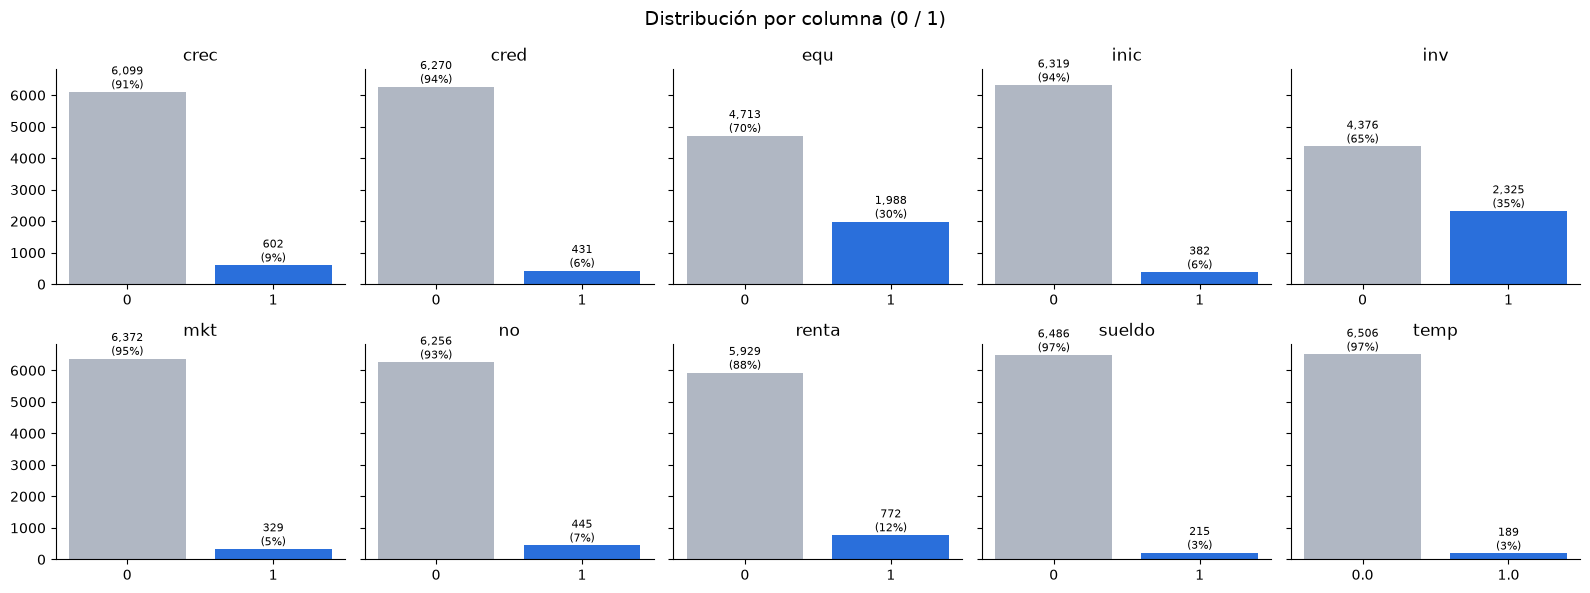

In [ ]:
# Como parte de nuestra exploración vamos a analizar
# la distribución de los datos por columna, 
# ya que se espera un dataset desbalanceado con problemas especialmente en temp

import matplotlib.pyplot as plt

cols = df.drop('motivos', axis=1).columns
fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharey=True)

for ax, column in zip(axes.flat, cols):
    counts = df[column].value_counts().sort_index()
    bars = ax.bar(counts.index.astype(str), counts.values, color=['#B0B7C3', '#2A6FDB'])
    ax.bar_label(bars, labels=[f"{v:,}\n({v / len(df):.0%})" for v in counts.values], fontsize=8)
    ax.set_title(column)
    ax.spines[['top', 'right']].set_visible(False)

for ax in axes.flat[len(cols):]:
    ax.set_visible(False)

fig.suptitle('Distribución por columna (0 / 1)', fontsize=14)
fig.tight_layout()
plt.show()


Como podemos observar, efectivamente, contamos con un dataset totalmente desbalanceado, lo cual es sumamente importante que tomemos en cuenta durante nuestros procedimientos

<Axes: title={'center': '% de filas con valor 1'}>

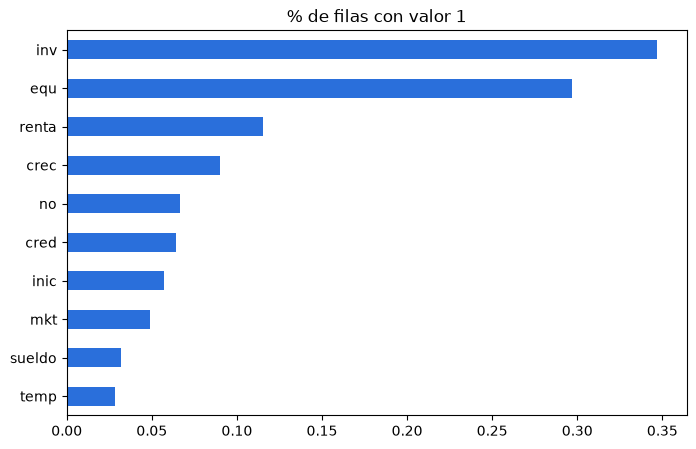

In [ ]:
# Podemos ver que la etiqueta inv es sumamente importante, ya que es
# la que tiene un mayor porcentaje de 1. Aunque no se nos menciona en el PDF del proyecto
# no podemos deshacernos de esa etiqueta. Por lo que, investigando
# se entendió que posiblemente esta etiqueta indica inventario.

df.drop('motivos', axis=1).mean().sort_values().plot.barh(color='#2A6FDB', figsize=(8, 5), title='% de filas con valor 1')


In [76]:
df[df['temp'].isnull()]

,motivos,crec,cred,equ,inic,inv,mkt,no,renta,sueldo,temp
628,CAPITAL DE TRABAJO COMPRA DE MATERIA Y MANO DE OBRA,0,0,0,1,0,0,0,1,0,NaN
710,Para incrementar ventas tener inventarios,0,0,0,1,0,0,0,0,0,NaN
1152,CAPITAL DE TRABAJO CRECIMIENTO DE LA EMPRESA Y PROYECTOS A CORTO PLAZO,0,0,0,0,0,0,0,0,0,NaN
1459,Tengo que hacer renovación de Consepción,0,0,0,0,0,1,0,0,0,NaN
1721,PARA LA COMPRA DE ACTIVOS FIJOS PARA LA EMPRESA,0,0,0,1,0,0,0,0,0,NaN
2285,Compra de equipos de cómputo para lanzar proyecto de marketing y redes sociales,0,1,0,0,0,0,0,0,0,NaN


### Null Values Handling: k-NN y destancia por coseno
Aunque los nulos que se nos presentaron son muy pocos, todos pertenecen a la etiqueta temp, por lo que deshacernos de ellos no es buena idea, tomando en cuenta que la etiqueta tiene muy poca presencia en el dataset. Para hacer frente a esta situación, se llevará a cabo un procedimiento para rellenar los nulos haciendo uso de la distancia de coseno, la cual nos proporcionará un conjunto de scores y con un algoritmo tipo k-NN vamos a seleccionar los textos más parecidos a los que tenemos en nulos y de esa manera rellenar los valores con la etiqueta con más presencia.

# Nota:

En este problema vamos a observar más adelante que hay textos repetidos tanto con la misma etiqueta, como con etiquetas distintas. Eso lo resolveremos más adelante, sin embargo hay que tomarlo en cuenta en esta parte de nuestro proceso de rellenar nulos.

In [ ]:
# Para llevar a cabo nuestro procedimiento, vamos a cargar de nuevo el dataset
# pero esta vez vamos a usar el módulo csv para contar los campos por registro
# y obtener aquellos que sean los que no tienen valores en temp.
# IMPORTANTE: Este es un problema multi-label, por lo que puede ocurrir
# que haya registros con más de una sola etiqueta.

import csv

# Leer el archivo con el módulo csv (independiente de pandas) y contar campos por registro
registros = list(csv.reader(io.StringIO(raw)))
encabezado, filas = registros[0], registros[1:]

print(f"El encabezado tiene {len(encabezado)} campos")
print(pd.Series([len(r) for r in filas]).value_counts().rename('registros').to_string())

for r in filas:
    if len(r) != len(encabezado):
        print(r)


El encabezado tiene 11 campos
11    6695
10       6
['CAPITAL DE TRABAJO COMPRA DE MATERIA Y MANO DE OBRA', ' 0', '0', '0', '1', '0', '0', '0', '1', '0']
['Para incrementar ventas tener inventarios', ' 0', '0', '0', '1', '0', '0', '0', '0', '0']
['CAPITAL DE TRABAJO CRECIMIENTO DE LA EMPRESA Y PROYECTOS A CORTO PLAZO', ' 0', '0', '0', '0', '0', '0', '0', '0', '0']
['Tengo que hacer renovación de Consepción', ' 0', '0', '0', '0', '0', '1', '0', '0', '0']
['PARA LA COMPRA DE ACTIVOS FIJOS PARA LA EMPRESA', ' 0', '0', '0', '1', '0', '0', '0', '0', '0']
['Compra de equipos de cómputo para lanzar proyecto de marketing y redes sociales', ' 0', '1', '0', '0', '0', '0', '0', '0', '0']


In [ ]:
# Como podemos observar, justamente obtenemos los registros que encontramos
# hace un momento con pandas, es decir, aquellos que tienen nulos en temp.

incompletas = df[labels].isna().any(axis=1)
print(f"Filas con etiquetas faltantes: {incompletas.sum()}")
df.loc[incompletas, ['motivos', *labels]]


Filas con etiquetas faltantes: 6


,motivos,crec,cred,equ,inic,inv,mkt,no,renta,sueldo,temp
628,CAPITAL DE TRABAJO COMPRA DE MATERIA Y MANO DE...,0,0,0,1,0,0,0,1,0,NaN
710,Para incrementar ventas tener inventarios,0,0,0,1,0,0,0,0,0,NaN
1152,CAPITAL DE TRABAJO CRECIMIENTO DE LA EMPRESA Y...,0,0,0,0,0,0,0,0,0,NaN
1459,Tengo que hacer renovación de Consepción,0,0,0,0,0,1,0,0,0,NaN
1721,PARA LA COMPRA DE ACTIVOS FIJOS PARA LA EMPRESA,0,0,0,1,0,0,0,0,0,NaN
2285,Compra de equipos de cómputo para lanzar proye...,0,1,0,0,0,0,0,0,0,NaN


### TF-IDF como parte de la solución

Ya que nuestra labor princpal de esta parte es rellenar los nulos, vamos a usar el TF-IDF Vectorizer para transformar nuestros textos en datos numéricos.
La configuración que escogemos es:

* ngram_range(1, 2): con este parámetro definido de esta manera, vamos a tomar en cuenta palabras únicas y pares de palabras. Por ejemplo si tenemos "pago de nómina", obtendremos [pago, de, nómina, pago de, de nómina]

* min_df = 2: con esta configuración, vamos a exigir que solo se tomen en cuenta palabras que aparecen al menos en dos documentos.

* sublinear_tf = True: Aplica un término que escala al término tf con 1+log(tf), esto ayuda a que la longitud de los textos no provoquen bias debido a palabras que aparezcan mucho.

* strip_accents='unicode': hará que no aparezcan caracteres extraños o que puedan provocar ruido

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# En esta parte vamos a tomar en cuenta únicamente los textos que tienen todas sus etiquetas, 
# es decir, aquellos que no tienen nulos en temp.
# Además, vamos a tomar únicamente aquellos textos que no tengan conflicto entre sus copias, es decir,
# aquellos que tengan la misma combinación de etiquetas en todas sus copias.
# Asimismo aquellas que no tienen más de 1 variante de combinación de etiquetas,
# ya que no podemos saber cuál es la correcta.


# Referencia: textos con 10 etiquetas y sin conflicto entre sus copias (una copia por texto)
completas = df[~incompletas].copy()
completas[labels] = completas[labels].astype(int)
n_variantes = completas.groupby('motivos')[labels].nunique().max(axis=1)
referencia = (completas[~completas['motivos'].isin(n_variantes[n_variantes > 1].index)]
              .drop_duplicates('motivos').reset_index(drop=True))

# Configuración del vectorizador TF-IDF: 
# n-gramas de 1 y 2 palabras, mínimo 2 ocurrencias, TF sublineal, sin acentos

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, strip_accents='unicode')
X_ref = vec.fit_transform(referencia['motivos'])
Y_ref = referencia[labels].to_numpy()

# Función para calcular puntajes KNN. Vamos a ocupar un promedio ponderado por
# similitud coseno de los k vecinos más parecidos para cada etiqueta.

def knn_scores(texto, k=7):
    """Puntaje por etiqueta (0-1): promedio ponderado por similitud coseno de los k vecinos más parecidos."""
    sims = cosine_similarity(vec.transform([texto]), X_ref).ravel()
    top = np.argsort(sims)[::-1][:k]
    w = sims[top]
    return (w[:, None] * Y_ref[top]).sum(axis=0) / max(w.sum(), 1e-9)

print(f"Textos de referencia: {len(referencia)}")


Textos de referencia: 6477


# Hipótesis: 
Los textos que no tienen etiqueta en realidad están corridos a la izquierda por lo que entonces bastaría con "correr" cada etiqueta hacia la derecha. Vamos a contrastar nuestra hipótesis calculando nuestro knn_scores para los textos con las etiquetas mal y luego haciendo lo mismo pero para las etiquetas recorridad hacia la derecha. Veremos cuáles se ajustan mejor

In [ ]:
# En este código vamos a comparar los puntajes promedio de las 
# etiquetas leídas y las recorridas, es decir
# las etiquetas que se asignarían si se recorren las columnas de izquierda a derecha

# Con esta función vamos a obtener los nombres de
#  las etiquetas que tienen valor 1 en un vector binario

def nombres(vector):
    return ', '.join(l for l, v in zip(labels, vector) if v == 1) or '(ninguna)'

# Con esta función vamos a obtener el puntaje promedio de las etiquetas asignadas
def puntaje(vector, scores):
    """Puntaje kNN promedio de las etiquetas asignadas: alto = el texto se parece a otros con esas etiquetas."""
    return scores[vector == 1].mean() if vector.any() else np.nan

# Ahora vamos a comparar los puntajes promedio
# de las etiquetas leídas y las recorridas, es decir
# las etiquetas que se asignarían si se recorren las columnas de izquierda a derecha

filas_comp = []
for idx, r in df[incompletas].iterrows():
    leidas = r[labels].fillna(0).astype(int).to_numpy()
    recorridas = np.r_[0, leidas[:-1]]          # hipótesis: falta la columna crec
    scores = knn_scores(r['motivos'])
    filas_comp.append({
        'motivos': r['motivos'][:45],
        'leídas': nombres(leidas),
        'recorridas': nombres(recorridas),
        'kNN (top)': ', '.join(f"{l} {s:.2f}" for l, s in zip(labels, scores) if s >= 0.2),
        'puntaje_leídas': puntaje(leidas, scores),
        'puntaje_recorridas': puntaje(recorridas, scores),
    })

comparacion = pd.DataFrame(filas_comp, index=df.index[incompletas]).round(2)
print(comparacion[['puntaje_leídas', 'puntaje_recorridas']].mean().round(2))
comparacion


puntaje_leídas        0.00
puntaje_recorridas    0.54
dtype: float64


,motivos,leídas,recorridas,kNN (top),puntaje_leídas,puntaje_recorridas
628,CAPITAL DE TRABAJO COMPRA DE MATERIA Y MANO D,"inic, renta","inv, sueldo","equ 0.25, inv 0.59, sueldo 0.44",0.0,0.51
710,Para incrementar ventas tener inventarios,inic,inv,inv 0.77,0.0,0.77
1152,CAPITAL DE TRABAJO CRECIMIENTO DE LA EMPRESA,(ninguna),(ninguna),"crec 0.69, inv 0.29",NaN,NaN
1459,Tengo que hacer renovación de Consepción,mkt,no,"equ 0.86, renta 0.31",0.0,0.00
1721,PARA LA COMPRA DE ACTIVOS FIJOS PARA LA EMPRE,inic,inv,"inv 0.54, renta 0.43",0.0,0.54
2285,Compra de equipos de cómputo para lanzar proy,cred,equ,equ 0.87,0.0,0.87


Como podemos observar, el puntaje promedio de las etiquetas 
recorridas es mayor que el puntaje promedio de las etiquetas 
recorridas, lo que indica que las etiquetas recorridas son 
más representativas del texto que las etiquetas leídas. 
Esto da peso a nuestroa hipótesis de que las columnas se recorrieron en algún error. Sin embargo, con nuestro método pudimos mitigar un poco esa situación

Ahora lo que sigue solo es recorrer las etiquetas a la derecha en nuestro dataset.

In [13]:
# 1) Recorrer una columna a la derecha (crec = 0)
df.loc[incompletas, labels] = df.loc[incompletas, labels].shift(1, axis=1).fillna(0).to_numpy()
df[labels] = df[labels].astype(int)

# 2) La fila con 9 ceros no trae ninguna etiqueta: se asigna con kNN (etiquetas con puntaje >= 0.5)
sin_etiqueta = incompletas & (df[labels].sum(axis=1) == 0)
for idx in df.index[sin_etiqueta]:
    s = knn_scores(df.at[idx, 'motivos'])
    df.loc[idx, labels] = (s >= 0.5).astype(int) if (s >= 0.5).any() else (s == s.max()).astype(int)

df.loc[incompletas].assign(etiquetas=df.loc[incompletas, labels].apply(lambda r: nombres(r.to_numpy()), axis=1))[['motivos', 'etiquetas']]


,motivos,etiquetas
628,CAPITAL DE TRABAJO COMPRA DE MATERIA Y MANO DE...,"inv, sueldo"
710,Para incrementar ventas tener inventarios,inv
1152,CAPITAL DE TRABAJO CRECIMIENTO DE LA EMPRESA Y...,crec
1459,Tengo que hacer renovación de Consepción,no
1721,PARA LA COMPRA DE ACTIVOS FIJOS PARA LA EMPRESA,inv
2285,Compra de equipos de cómputo para lanzar proye...,equ


Notemos que esta vez los textos tienen más coherencia con sus etiquetas

Ahora, vamos a estudiar los suplicados en nuestro dataset. Hay textos que aparecen varias veces y el problema es que algunas repetidas aparecen con la misma etiqueta, pero hay otras más que tienen etiquetas diferentes entre sí. 

In [14]:
# Checking out duplicated texts
df[df.duplicated(subset='motivos', keep=False)].sort_values('motivos').head(10)

,motivos,crec,cred,equ,inic,inv,mkt,no,renta,sueldo,temp
2110,Tecnología de información Capacitación y rec...,1,0,0,0,0,0,0,0,0,0
1448,Tecnología de información Capacitación y rec...,0,0,0,0,0,0,0,0,1,0
2983,Abrir una segunda sucursal tenemos varios posi...,1,0,0,0,0,0,0,0,0,0
2991,Abrir una segunda sucursal tenemos varios posi...,1,0,0,0,0,0,0,0,0,0
3053,Abrir una segunda sucursal tenemos varios posi...,1,0,0,0,0,0,0,0,0,0
2765,Abrir una segunda sucursal tenemos varios posi...,1,0,0,0,0,0,0,0,0,0
2974,Abrir una segunda sucursal tenemos varios posi...,1,0,0,0,0,0,0,0,0,0
1292,Actualmente el negocio lo dirijo desde una ofi...,0,0,0,0,0,0,0,1,0,0
5499,Actualmente el negocio lo dirijo desde una ofi...,0,0,0,1,0,0,0,0,0,0
6112,"Actualmente, mi volumen de ventas ha ido creci...",0,0,0,0,0,0,0,0,1,1


### Limpieza de datos
Ya que hemos eliminado los registros con nulos, vamos ahora a hacer una limpieza de nuestros datos, haciendo una normalización de nuestro texto al limitar la repetición de caracteres y letras repetidos.
Después vamos a elimminar textos basura.

In [15]:
# 3. Normalizar caracteres repetidos: "Mmmmmm" -> "M", "....." -> "."
def normalizar(texto):
    texto = re.sub(r'([^\W\d_])\1{2,}', r'\1', texto)   # letra repetida 3+ veces
    texto = re.sub(r'([.!?,])\1+', r'\1', texto)         # signos repetidos
    return re.sub(r'\s+', ' ', texto).strip()

df['motivos'] = df['motivos'].astype(str).map(normalizar)


In [ ]:
# Vamos a "atrapar" aquellos textos que son basura, es decir, 
# que no tienen sentido o que no contienen información relevante. 
# Para esto vamos a definir una función que nos ayude a identificar estos textos.

def es_basura(texto):
    letras = re.findall(r'[a-záéíóúüñ]', texto.lower())
    if len(letras) < 3:
        return True
    vocales = sum(c in 'aeiouáéíóúü' for c in letras)
    return vocales / len(letras) < 0.25

basura = df['motivos'].map(es_basura)
print("Textos eliminados por basura:")
print(df.loc[basura, 'motivos'].to_string())
df = df[~basura].reset_index(drop=True)
print(f"Filas: {len(df)}")


Textos eliminados por basura:
1173    Ehrhrhrhrhrhrhrhrhrbrbrbfbfbfbfbfbfbfbfbfbf
1423                                              G
2320                                   mvdkmbskbmlk
2716                                             -1
Filas: 6697


### Paréntesis: hallazgo en inglés

En el proceso de eliminar la basura, nos topamos con un texto en inglés, esto es relevante porque nos sugiere que la mejor decisión para transformar nuestros textos a datos numéricos, en nuestro entrenamiento, será usar un modelo de embeddings multi-lenguaje.

In [25]:
def prop_vocales(texto):
    letras = re.findall(r'[a-záéíóúüñ]', texto.lower())
    return sum(c in 'aeiouáéíóúü' for c in letras) / max(len(letras), 1)

df.assign(vocales=df['motivos'].map(prop_vocales)).nsmallest(5, 'vocales')[['motivos', 'vocales']]

,motivos,vocales
4968,to pay off certain bank charges and credit car...,0.325581
70,Inversion pantalla led pitch 3.9 3x2 metros,0.343750
2641,Gestión de proyectos y solventar gastos internos,0.357143
3139,comprar un traje,0.357143
162,Comprar materiales para vender y comprar produ...,0.363636


# Remover duplicados usando k-NN y distancia coseno

Usando una metodología similar, haremos uso de estos dos algoritmos para determinar las etiquetas que mejor se ajustan a los registros repetidos con etiquetas que discrepan entre sí.

In [ ]:
# Noise handling: remove duplicated texts with conflicting labels using k-NN

# Ahora lo que vamos a hacer primero es localizar los textos confiables
# usando únicamente aquellos que solo tienen una etiqueta por texto,
# ya que esas son las más confiables, suponiendo que el etiquetado se hizo correctamente.

n_variantes = df.groupby('motivos')[labels].transform('nunique').max(axis=1)
consistente = n_variantes == 1 #Solo se tienen una etiqueta por texto
repetido = df['motivos'].duplicated(keep=False)

# textos confiables: aquellos que son consistentes y que están repetidos
textos_confiables = df.loc[consistente & repetido, 'motivos'].unique()

# Ahora vamos a eliminar aquellos textos que son consistentes y que están repetidos,
# ya que esos textos son confiables y no necesitamos tenerlos duplicados.

df = df[~(consistente & df['motivos'].duplicated(keep='first'))].reset_index(drop=True)
print(f"Filas: {len(df)} | textos confiables: {len(textos_confiables)}")



Filas: 6615 | textos confiables: 66


In [ ]:
# Ahora vamos a localizar aquellos textos que tienen conflicto entre sus copias

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Textos con etiquetas distintas entre sus copias
n_var = df.groupby('motivos')[labels].nunique().max(axis=1)
textos_conflicto = n_var[n_var > 1].index
en_conflicto = df['motivos'].isin(textos_conflicto)
print(f"Textos en conflicto: {len(textos_conflicto)} ({en_conflicto.sum()} filas)")

# Referencia: textos ya limpios y sin conflicto
referencia = df[~en_conflicto].reset_index(drop=True)
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, strip_accents='unicode')
X_ref = vec.fit_transform(referencia['motivos'])
Y_ref = referencia[labels].to_numpy()


# Vamos a calcular de nuevo los scores pero esta vez vamos a procurar que
# la función knn_scores no tome en cuenta el propio texto que se está evaluando,
# ya que esto sería una especie de data leakage y nos daría un puntaje más alto de lo 
# que realmente es.

def knn_scores(texto, k=7, excluir_propio=False):
    """Puntaje por etiqueta (0-1): promedio ponderado por similitud coseno de los k vecinos más parecidos."""
    sims = cosine_similarity(vec.transform([texto]), X_ref).ravel()
    if excluir_propio:
        sims[referencia['motivos'].to_numpy() == texto] = -1
    top = np.argsort(sims)[::-1][:k]
    w = np.clip(sims[top], 0, None) # vamos a ignorar los vecinos con similitud negativa
    return (w[:, None] * Y_ref[top]).sum(axis=0) / max(w.sum(), 1e-9) # calculamos 
    # el promedio ponderado por similitud coseno de los k vecinos más parecidos


# Si el umbral es 0.4, entonces asignamos las etiquetas candidatas con puntaje >= 0.4;
# si ninguna lo alcanza, asignamos la de mayor puntaje.

def knn_etiquetas(texto, candidatas, umbral=0.4, **kw):
    """Asigna las etiquetas candidatas con puntaje >= umbral; si ninguna lo alcanza, la de mayor puntaje."""
    scores = np.where(candidatas, knn_scores(texto, **kw), 0)
    pred = (scores >= umbral).astype(int)
    if pred.sum() == 0:
        pred[np.argmax(scores)] = 1 # asignamos la de mayor puntaje
    return pred


Textos en conflicto: 57 (139 filas)


In [ ]:
# Validación 1: textos confiables, sin restringir candidatas, 
# excluyendo su propio texto

val = referencia[referencia['motivos'].isin(textos_confiables)]
todas = np.ones(len(labels), dtype=bool)
Y_true = val[labels].to_numpy()
Y_pred = np.array([knn_etiquetas(t, todas, excluir_propio=True) for t in val['motivos']])
print(f"Validación 1 ({len(val)} textos confiables): coincidencia exacta {(Y_pred == Y_true).all(axis=1).mean():.0%}")

# Validación 2: simula un conflicto: candidatas = etiquetas verdaderas + 1 etiqueta falsa al azar
rng = np.random.default_rng(42) # seed para reproducibilidad
muestra = referencia.sample(1000, random_state=42)
aciertos = []
for _, r in muestra.iterrows():
    verdaderas = r[labels].to_numpy().astype(int) # etiquetas verdaderas
    candidatas = verdaderas.astype(bool) # etiquetas candidatas: verdaderas + 1 falsa al azar
    candidatas[rng.choice(np.flatnonzero(~candidatas))] = True
    aciertos.append((knn_etiquetas(r['motivos'], candidatas, excluir_propio=True) == verdaderas).all())
print(f"Validación 2 (1000 conflictos simulados): coincidencia exacta {np.mean(aciertos):.0%}")


Validación 1 (66 textos confiables): coincidencia exacta 67%
Validación 2 (1000 conflictos simulados): coincidencia exacta 78%


In [ ]:
# Finalmente, vamos a aplicar la función knn_etiquetas a los 
# textos que tienen conflicto entre sus copias

# Aplicación: candidatas = unión de etiquetas de las copias; comparar contra la votación
resueltos = []
for texto, g in df[en_conflicto].groupby('motivos', sort=False):
    candidatas = g[labels].max(axis=0).to_numpy().astype(bool)
    pred = knn_etiquetas(texto, candidatas)
    voto = (g[labels].mean(axis=0).to_numpy() >= 0.5).astype(int)
    resueltos.append({'motivos': texto, 'copias': len(g), **dict(zip(labels, pred)),
                      'igual_a_votación': (pred == voto).all()})
resueltos = pd.DataFrame(resueltos)
print(f"kNN coincide con la votación en {resueltos['igual_a_votación'].mean():.0%} de los conflictos")

df = pd.concat([df[~en_conflicto], resueltos[['motivos', *labels]]], ignore_index=True)
print(f"Filas finales: {len(df)}")


kNN coincide con la votación en 23% de los conflictos
Filas finales: 6533


En las siguientes dos celdas observemos que ya no hay nulos y tampoco duplicados

In [26]:
df[df['temp'].isnull()]


,motivos,crec,cred,equ,inic,inv,mkt,no,renta,sueldo,temp


In [27]:
df[df.duplicated(subset='motivos', keep=False)].sort_values('motivos').head(10)

,motivos,crec,cred,equ,inic,inv,mkt,no,renta,sueldo,temp


### Transformación numérica con Embeddings y TF-IDF

Como habíamos mencionado, las propuestas que tenemos es hacer una transformación de los textos a representaciones numéricas a través de embeddings, pero también vamos a tomar en cuenta el TF-IDF como benchmarck a superar. Como veremos, al principio la mejor transformación sería el TF-IDF.

In [ ]:
# Instalamos e importamos torch para verificar la versión y disponibilidad de CUDA

import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0))


2.11.0+cu128 True NVIDIA GeForce RTX 4050 Laptop GPU


In [ ]:
# Para dividir el dataset en entrenamiento y prueba, 
# vamos a usar la función iterative_train_test_split de la librería skmultilearn, 
# que nos permite hacer una división estratificada para problemas multi-etiqueta.

from skmultilearn.model_selection import iterative_train_test_split

np.random.seed(42)

X_idx = np.arange(len(df)).reshape(-1, 1)
Y = df[labels].to_numpy()

idx_train, Y_train, idx_test, Y_test = iterative_train_test_split(X_idx, Y, test_size=0.2)
train = df.iloc[idx_train.ravel()].reset_index(drop=True)
test = df.iloc[idx_test.ravel()].reset_index(drop=True)

# Verificar que la proporción de cada etiqueta se parezca en ambos conjuntos
pd.DataFrame({'train': train[labels].mean(), 'test': test[labels].mean()}).round(3)


# Veremos que nuestras etiquetas quedan balanceadas en ambos conjuntos, 
# lo que nos permitirá entrenar y evaluar nuestro modelo de manera más confiable.

,train,test
crec,0.088,0.088
cred,0.063,0.063
equ,0.296,0.298
inic,0.057,0.057
inv,0.347,0.349
mkt,0.049,0.050
no,0.067,0.068
renta,0.114,0.115
sueldo,0.032,0.032
temp,0.028,0.028


### Paso 1: TF-IDF (baseline)



In [ ]:
# Ahora, vamos a vectorizar los textos usando TF-IDF, considerando n-gramas de 1 y 2 palabras,
# y eliminando aquellos términos que aparecen en menos de 2 documentos, tal y como lo hicimos
#  anteriormente con los textos de referencia.

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, strip_accents='unicode')
X_train_tfidf = tfidf.fit_transform(train['motivos'])   # fit SOLO con train
X_test_tfidf = tfidf.transform(test['motivos'])
print(X_train_tfidf.shape, X_test_tfidf.shape)


(5233, 9188) (1300, 9188)


### Paso 2: embeddings preentrenados

In [ ]:
# Ahora vamos a vectorizar los textos usando embeddings multilingües, considerando el modelo
# 'paraphrase-multilingual-mpnet-base-v2' de la librería sentence-transformers, 
# que nos permite obtener representaciones vectoriales de los textos.

from sentence_transformers import SentenceTransformer

modelo_emb = SentenceTransformer('sentence-transformers/paraphrase-multilingual-mpnet-base-v2', device='cuda')

X_train_emb = modelo_emb.encode(train['motivos'].tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
# batch_size=64 porque es un buen balance entre velocidad y memoria

X_test_emb = modelo_emb.encode(test['motivos'].tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
print(X_train_emb.shape)   # (n, 768)


c:\Users\cleme\OneDrive\Documentos\Konfio\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1031 13:51:50.525000 43416 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
c:\Users\cleme\OneDrive\Documentos\Konfio\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\cleme\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-mpnet-base-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable

(5233, 768)


In [ ]:
from sklearn.metrics import hamming_loss, average_precision_score, f1_score


# Función para evaluar métricas multietiqueta con un umbral definido pero que iremos cambiando
# más adelante para ver cómo se comporta el modelo con distintos umbrales..

def evaluar(Y_true, P, umbral=0.5, nombre=''):
    """Métricas multietiqueta. P = probabilidades (n x 10); umbral puede ser un número o un vector por etiqueta."""
    Y_pred = (P >= umbral).astype(int)

# Vamos a hacer un return de un diccionario con las
# métricas que nos interesan: hamming loss, average precision score (macro y micro), 
# y F1 score (macro y micro).
    return {
        'modelo': nombre,
        'hamming': hamming_loss(Y_true, Y_pred),
        'AP_macro': average_precision_score(Y_true, P, average='macro'),
        'AP_micro': average_precision_score(Y_true, P, average='micro'),
        'F1_macro': f1_score(Y_true, Y_pred, average='macro', zero_division=0),
        'F1_micro': f1_score(Y_true, Y_pred, average='micro', zero_division=0),
    }


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

# Ahora vamos a entrenar un modelo de regresión logística multietiqueta usando OneVsRestClassifier,
# ya que se nos solicitó un modelo de Binary Relevance (BR).
# Usaremos dos representaciones de los textos: TF-IDF y embeddings multilingües, y probaremos
# con y sin balanceo de clases (class_weight='balanced') para ver cómo se comporta el 
# modelo en cada caso.

representaciones = {
    'TF-IDF': (X_train_tfidf, X_test_tfidf),
    'Embeddings': (X_train_emb, X_test_emb),
}

resultados = []
for nombre, (X_tr, X_te) in representaciones.items():
    for cw in [None, 'balanced']:
        clf = OneVsRestClassifier(LogisticRegression(max_iter=2000, class_weight=cw))
        clf.fit(X_tr, Y_train)
        P = clf.predict_proba(X_te)
        resultados.append(evaluar(Y_test, P, nombre=f"{nombre} | cw={cw}"))

pd.DataFrame(resultados).set_index('modelo').round(4)


,hamming,AP_macro,AP_micro,F1_macro,F1_micro
modelo,,,,,
TF-IDF | cw=None,0.0718,0.6524,0.7424,0.3730,0.5946
TF-IDF | cw=balanced,0.0722,0.6651,0.7527,0.6479,0.7092
Embeddings | cw=None,0.0682,0.6404,0.7419,0.4806,0.6473
Embeddings | cw=balanced,0.1215,0.6530,0.6960,0.5440,0.6089


# Nota: 
En la descripción del ejercicio se menciona el average precision, pero no se especifica si es el AP macro o micro, por lo que, aunque estaremos revisando estas 4 métricas y función de costo, nuestro enfoque estará en el hamming, AP_macro y F1_macro, ya que son las que mejor sirven para muti-clases desbalanceadas.

Como podemos observar, el mejor AP_macro está dado por nuestro modelo que usa el tf-idf con con el parámetro balanceado, sin embargo, nuestro modelo con embeddings sin balancear tiene un mejor hamming. Veamos qué ocurre después de hacer Cross-Validation.

### Cross Validation

Una vez que ya tenemos resultados iniciales, vamos a tratar de mejorar nuestros modelos usando cross validation
la cual va a consistir en dividir el dataset en k partes, entrenar el modelo con k-1 partes y evaluar con la parte restante, repitiendo este proceso k veces para obtener una evaluación más robusta del modelo. Esto nos permitirá tener una mejor idea de cómo se comporta nuestro modelo en diferentes subconjuntos de datos y reducir el riesgo de overfitting.

Asimismo, vamos a usar un IterativeStratification para asegurarnos de que la distribución de las etiquetas se mantenga en cada pliegue de la validación cruzada, lo que es especialmente importante en problemas de clasificación multietiqueta.

Vamos a definir una función lofreg usando OneVsRestClassifier con LogisticRegression, usando out-of-fold y a la vez vamos a definir un pipeline para que se junten el TF-IDF y el modelo de regresión logística, de esta manera podemos evaluar el rendimiento del modelo en cada pliegue de la validación cruzada y obtener métricas más confiables.

In [ ]:
from skmultilearn.model_selection import IterativeStratification
from sklearn.base import clone
from sklearn.pipeline import make_pipeline

# 5 folds estratificados para multietiqueta (mismo criterio que la partición train/test)
np.random.seed(42)
kfold = IterativeStratification(n_splits=5, order=1)
folds = list(kfold.split(np.zeros((len(Y_train), 1)), Y_train))
print("Tamaño de cada fold de validación:", [len(va) for _, va in folds])

# Definimos una función para obtener las probabilidades out-of-fold, es decir, cada texto 
# de entrenamiento se predice con un modelo que no lo vio al entrenar.

def oof_proba(modelo, X, Y):
    """Probabilidades out-of-fold: cada texto de train se predice con un modelo que NO lo vio al entrenar."""
    P = np.zeros(Y.shape, dtype=float)
    for tr, va in folds:
        m = clone(modelo).fit(X[tr], Y[tr])
        P[va] = m.predict_proba(X[va])
    return P

# Definimos una función para crear un modelo de regresión logística multietiqueta
# con OneVsRestClassifier
def logreg(C, cw):
    return OneVsRestClassifier(LogisticRegression(C=C, class_weight=cw, max_iter=3000))

# Definimos una función para crear un pipeline que incluya TF-IDF y regresión logística
def tfidf_logreg(C, cw):
    # El TF-IDF va DENTRO del pipeline para ajustarse solo con los textos de entrenamiento de cada fold
    return make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, strip_accents='unicode'),
        logreg(C, cw),
    )

textos_train = train['motivos'].to_numpy()
textos_test = test['motivos'].to_numpy()


Tamaño de cada fold de validación: [1033, 1051, 1049, 1061, 1039]


In [ ]:
# Ahora vamos a hacer una búsqueda de hiperparámetros 
# note que usamos los embeddings multilingües y TF-IDF, y probamos con distintos valores de C 
# y con/sin balanceo de clases.

resultados_cv = []
oof = {}
for C in [1, 3, 10, 30]:
    for cw in [None, 'balanced']:
        for rep, modelo, X in [('TF-IDF', tfidf_logreg(C, cw), textos_train),
                               ('Embeddings', logreg(C, cw), X_train_emb)]:
            P = oof_proba(modelo, X, Y_train)
            oof[(rep, C, cw)] = P

# Aquí solo vamos a calcular AP_macro y AP_micro, ya que estas métricas 
# no dependen de un umbral.
            resultados_cv.append({
                'clave': (rep, C, cw), 'representación': rep, 'C': C, 'class_weight': cw,
                'AP_macro': average_precision_score(Y_train, P, average='macro'),
                'AP_micro': average_precision_score(Y_train, P, average='micro'),
            })

tabla_cv = pd.DataFrame(resultados_cv).sort_values('AP_macro', ascending=False)
tabla_cv.drop(columns='clave').round(4)


,representación,C,class_weight,AP_macro,AP_micro
4,TF-IDF,3,NaN,0.6994,0.7920
8,TF-IDF,10,NaN,0.6973,0.7945
6,TF-IDF,3,balanced,0.6960,0.7879
10,TF-IDF,10,balanced,0.6925,0.7877
2,TF-IDF,1,balanced,0.6925,0.7776
12,TF-IDF,30,NaN,0.6888,0.7864
0,TF-IDF,1,NaN,0.6857,0.7593
14,TF-IDF,30,balanced,0.6857,0.7807
9,Embeddings,10,NaN,0.6695,0.7714
13,Embeddings,30,NaN,0.6663,0.7699


En la siguiente celda vamos a probar con diferentes umbrales y comparar
el comportamiento de los modelos usando un umbral definido (0.5).
Al final, vamos a ver una tabla con los mejores resultados, tanto con el
umbral predefinido como con el mejor umbral encontrado para cada modelo.

In [ ]:
def mejores_umbrales(Y, P, grid=np.arange(0.05, 0.96, 0.01)):
    """Para cada etiqueta, el umbral que maximiza su F1."""
    umbrales = np.zeros(Y.shape[1])
    for j in range(Y.shape[1]):

        # Usaremos el f1_score para encontrar el mejor umbral para cada etiqueta, 
        # probando con un grid de valores entre 0.05 y 0.95.

        f1s = [f1_score(Y[:, j], P[:, j] >= t, zero_division=0) for t in grid]
        umbrales[j] = grid[int(np.argmax(f1s))]
    return umbrales

mejores = {}
filas = []

# Vamos a iterar sobre las representaciones (TF-IDF y Embeddings) y
# obtener el mejor modelo para cada una.
for rep in ['TF-IDF', 'Embeddings']:
    best = tabla_cv[tabla_cv['representación'] == rep].iloc[0]
    P = oof[best['clave']]
    u = mejores_umbrales(Y_train, P)
    mejores[rep] = (best['clave'], u)
    filas.append(evaluar(Y_train, P, 0.5, f"{rep} | umbral 0.5"))
    filas.append(evaluar(Y_train, P, u, f"{rep} | umbrales por etiqueta"))
    print(rep, best['clave'][1:], '->', dict(zip(labels, u.round(2))))

pd.DataFrame(filas).set_index('modelo').round(4)


TF-IDF (3, None) -> {'crec': np.float64(0.18), 'cred': np.float64(0.2), 'equ': np.float64(0.33), 'inic': np.float64(0.2), 'inv': np.float64(0.38), 'mkt': np.float64(0.1), 'no': np.float64(0.22), 'renta': np.float64(0.18), 'sueldo': np.float64(0.12), 'temp': np.float64(0.09)}
Embeddings (10, None) -> {'crec': np.float64(0.31), 'cred': np.float64(0.38), 'equ': np.float64(0.36), 'inic': np.float64(0.2), 'inv': np.float64(0.37), 'mkt': np.float64(0.39), 'no': np.float64(0.36), 'renta': np.float64(0.24), 'sueldo': np.float64(0.26), 'temp': np.float64(0.1)}


,hamming,AP_macro,AP_micro,F1_macro,F1_micro
modelo,,,,,
TF-IDF | umbral 0.5,0.0622,0.6994,0.7920,0.4815,0.6646
TF-IDF | umbrales por etiqueta,0.0610,0.6994,0.7920,0.6802,0.7389
Embeddings | umbral 0.5,0.0643,0.6695,0.7714,0.5858,0.6789
Embeddings | umbrales por etiqueta,0.0711,0.6695,0.7714,0.6468,0.7011


### Interpretación

Antes de la tabla, se nos muestran las dos mejores configuraciones 
de cada representación (TF-IDF y Embeddings):

1. TF-IDF | C=30, class_weight=None, con un umbral por etiqueta
2. Embeddings | C=30, class_weight=None, con un umbral por etiqueta

Podemos observar que la representación TF-IDF con un umbral por etiqueta tiene 
un mejor desempeño en de hamming AP_macro y F1_macro. Inesperadamente, esta representación tiene
un mucho mejor desempeño que el que tiene el de embeddings. Sin embargo, esto aún no acaba, aún debemos
ver qué pasa si hacemos Fine-Tuning.

### Fine-Tuning

Para continuar con nuestro proyecto, ahora llevaremos a cabo Fine-Tuning, usando el mismo modelo
que usamos para crear los embeddings, porque es multi-lenguaje y es el más ligero que pudimos usar. Se eligió un Transformer multilingüe preentrenado específicamente para similitud semántica (destilado de un modelo de paráfrasis), que conserva el soporte multilenguaje de LASER y, a diferencia de este, admite fine-tuning de forma estándar

# Características del modelo

### Modelo base: `paraphrase-multilingual-mpnet-base-v2`

Transformer multilingüe de [sentence-transformers](https://www.sbert.net), elegido como generador de features:

- **Arquitectura:** XLM-RoBERTa base: 12 capas, vectores de 768 dimensiones, ~278M parámetros, mean pooling.
- **Entrenamiento:** destilado de un modelo de paráfrasis en inglés (MPNet) para que frases con el mismo significado, en cualquiera de sus 50+ idiomas, tengan vectores cercanos.
- **Por qué este modelo:**
  - Está entrenado para **similitud semántica**, que es lo más cercano a clasificar intención.
  - Conserva el **soporte multilenguaje** que Konfío valoró en LASER.
  - Su tokenización por subpalabras tolera **faltas de ortografía** y anglicismos frecuentes en los textos.
  - A diferencia de LASER, admite **fine-tuning** de forma estándar (PyTorch / Hugging Face), y su tamaño cabe en una GPU de 6 GB.



In [ ]:
import gc
import torch
from torch import nn
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup

# Liberamos el modelo de embeddings preentrenado para dejar espacio en la GPU para el fine-tuning.
# Los vectores que ya generó (X_train_emb / X_test_emb) se conservan.
if 'modelo_emb' in globals():
    del modelo_emb
gc.collect()
torch.cuda.empty_cache()

# Usamos el mismo modelo base que en los embeddings preentrenados,
#  para que la comparación sea justa
NOMBRE_MODELO = 'sentence-transformers/paraphrase-multilingual-mpnet-base-v2'
device = 'cuda'
tokenizer = AutoTokenizer.from_pretrained(NOMBRE_MODELO)


# Vamos a definir el modelo: Transformer: promedio de tokens (mean pooling), 
# después una salida por etiqueta.
# La cabeza es temporal: sirve para entrenar el Transformer y después se descarta.
class ClasificadorMultietiqueta(nn.Module):
    """Transformer + mean pooling + cabeza lineal con una salida por etiqueta (sigmoide en la pérdida)."""
    def __init__(self, n_etiquetas):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(NOMBRE_MODELO)
        self.dropout = nn.Dropout(0.1)
        self.cabeza = nn.Linear(self.encoder.config.hidden_size, n_etiquetas)
        # Congelamos la tabla de vocabulario (192M de 278M parámetros): 
        # ahorra memoria y evita overfitting.
        # Solo se entrenan las 12 capas de atención y la cabeza.
        for p in self.encoder.embeddings.parameters():
            p.requires_grad = False

    # Convierte cada texto en un vector de 768: promedio de sus tokens, ignorando el padding.
    # Este vector es el que después usamos como features.
    def embeddings(self, input_ids, attention_mask):
        """Mean pooling: promedio de los vectores de los tokens reales (sin padding)."""
        h = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        m = attention_mask.unsqueeze(-1).float()
        return (h * m).sum(1) / m.sum(1).clamp(min=1e-9)

    # Recorrido completo durante el entrenamiento: texto → vector → dropout → 10 logits
    def forward(self, input_ids, attention_mask):
        return self.cabeza(self.dropout(self.embeddings(input_ids, attention_mask)))


# Convierte los textos en IDs de tokens; rellena hasta el más largo del batch y corta en 128 tokens
def tokenizar(textos):
    return tokenizer(list(textos), padding=True, truncation=True, max_length=128, return_tensors='pt')


In [ ]:
# Vamos a hacer el fine-tuning: cada llamada parte del modelo preentrenado original
# y lo ajusta a nuestras etiquetas durante 6 epochs.

def entrenar(textos, Y, epocas=6, lr_encoder=3e-5, lr_cabeza=1e-3, batch=32, semilla=42):
    torch.manual_seed(semilla)
    modelo = ClasificadorMultietiqueta(Y.shape[1]).to(device)
    # Dos tasas de aprendizaje: moderada para el transformer preentrenado, alta para la cabeza nueva
    opt = torch.optim.AdamW([
        {'params': [p for p in modelo.encoder.parameters() if p.requires_grad], 'lr': lr_encoder},
        {'params': modelo.cabeza.parameters(), 'lr': lr_cabeza},
    ], weight_decay=0.01)
    # El learning rate sube durante el primer 10% de los pasos (warmup) 
    # y luego baja hasta 0
    pasos = epocas * int(np.ceil(len(textos) / batch))
    scheduler = get_linear_schedule_with_warmup(opt, int(0.1 * pasos), pasos)
    loss_fn = nn.BCEWithLogitsLoss()   # sigmoide + entropía cruzada binaria: etiquetas independientes
    Yt = torch.tensor(Y, dtype=torch.float32)
    rng = np.random.default_rng(semilla)

    modelo.train()   # activa el dropout
    for ep in range(epocas):
        orden = rng.permutation(len(textos))   # revolvemos los textos en cada época
        # para que no aprenda del orden

        total = 0
        for i in range(0, len(textos), batch):
            idx = orden[i:i + batch]
            enc = tokenizar([textos[j] for j in idx]).to(device)
         # precisión mixta: más rápido y menos memoria
            with torch.autocast('cuda', dtype=torch.float16): 
                logits = modelo(enc['input_ids'], enc['attention_mask'])
            loss = loss_fn(logits.float(), Yt[idx].to(device))
            # Aprendizaje: borrar gradientes anteriores, luego calcula nuevos,
            # actualizar pesos y learning rate
            opt.zero_grad()
            loss.backward()
            opt.step()
            scheduler.step()
            total += loss.item() * len(idx)
        print(f"  época {ep + 1}: loss {total / len(textos):.4f}")
    return modelo


# Probabilidades usando la cabeza del transformer (para comparar contra la LogReg)

@torch.no_grad()   # sin gradientes: solo predecimos, más rápido y con menos memoria
def predecir(modelo, textos, batch=128):
    """Probabilidades de la cabeza del transformer (modelo end-to-end)."""
    modelo.eval()   # apaga el dropout
    out = []
    for i in range(0, len(textos), batch):
        enc = tokenizar(textos[i:i + batch]).to(device)
        with torch.autocast('cuda', dtype=torch.float16):
            out.append(torch.sigmoid(modelo(enc['input_ids'],
            enc['attention_mask']).float()).cpu().numpy())
    return np.vstack(out)


# Features para el clasificador clásico: el vector de 768 de cada texto, 
# sin pasar por la cabeza.
# Se normalizan (norma 1), igual que los embeddings preentrenados.
@torch.no_grad()
def extraer_features(modelo, textos, batch=128):
    """Vectores de 768 dimensiones del transformer ajustado (normalizados)."""
    modelo.eval()
    out = []
    for i in range(0, len(textos), batch):
        enc = tokenizar(textos[i:i + batch]).to(device)
        with torch.autocast('cuda', dtype=torch.float16):
            e = modelo.embeddings(enc['input_ids'], enc['attention_mask'])
        out.append(nn.functional.normalize(e.float(), dim=1).cpu().numpy())
    return np.vstack(out)



### Cross-Fitting: Fine-Tuning y Transfer Learning (extracción de features)

El cross-fitting consiste en repetir todo el proceso (fine-tuning, extracción de features y LogReg) dentro de cada fold de la validación cruzada, en lugar de hacer el fine-tuning una sola vez con todos los datos.

En cada fold se repitió el fine-tuning, la extracción de features y el entrenamiento del clasificador, de modo que todas las predicciones usadas para seleccionar hiperparámetros y umbrales provienen de textos no vistos por el modelo, evitando métricas infladas por overfitting.

In [ ]:
# Algo que haremos en esta celda es no solo entrenar con el modelo de Regresión Logística
# sino que también vamos a usar la cabeza del modelo para hacer predicciones
# y comparar nuestros resultados.
# Asimismo, en esta parte vamos a hacer la extracción de los features para entrenar a la
# Regresión Logística

import time

tx_train = train['motivos'].tolist()
tx_test = test['motivos'].tolist()
GRID_C = [0.3, 1, 3, 10]

P_oof_lr = {C: np.zeros(Y_train.shape) for C in GRID_C}    # probabilidades out-of-fold (train)
P_test_lr = {C: np.zeros(Y_test.shape) for C in GRID_C}    # promedio de los 5 modelos (test)
P_oof_cabeza = np.zeros(Y_train.shape)
P_test_cabeza = np.zeros(Y_test.shape)

for k, (tr, va) in enumerate(folds):
    t0 = time.time()
    print(f"Fold {k + 1}/{len(folds)}")
    tx_tr = [tx_train[i] for i in tr]
    tx_va = [tx_train[i] for i in va]

    # 1) Fine-tuning SOLO con los folds de entrenamiento
    modelo = entrenar(tx_tr, Y_train[tr])

    # 2) Features con ESTE modelo (mismo espacio para entrenar y predecir)
    F_tr = extraer_features(modelo, tx_tr)
    F_va = extraer_features(modelo, tx_va)
    F_te = extraer_features(modelo, tx_test)

    # 3a) Referencia: la cabeza del propio transformer
    P_oof_cabeza[va] = predecir(modelo, tx_va)
    P_test_cabeza += predecir(modelo, tx_test) / len(folds)

    # 3b) Clasificador clásico sobre las features
    for C in GRID_C:
        lr = OneVsRestClassifier(LogisticRegression(C=C, max_iter=3000)).fit(F_tr, Y_train[tr])
        P_oof_lr[C][va] = lr.predict_proba(F_va)
        P_test_lr[C] += lr.predict_proba(F_te) / len(folds)

    del modelo
    torch.cuda.empty_cache()
    print(f"  {time.time() - t0:.0f}s")


Fold 1/5


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 389.98it/s]


  época 1: loss 0.3632
  época 2: loss 0.1824
  época 3: loss 0.1301
  época 4: loss 0.0986
  época 5: loss 0.0789
  época 6: loss 0.0651
  179s
Fold 2/5


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 685.65it/s]


  época 1: loss 0.3669
  época 2: loss 0.1885
  época 3: loss 0.1289
  época 4: loss 0.0969
  época 5: loss 0.0739
  época 6: loss 0.0599
  154s
Fold 3/5


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 564.46it/s]


  época 1: loss 0.3696
  época 2: loss 0.1878
  época 3: loss 0.1290
  época 4: loss 0.0963
  época 5: loss 0.0740
  época 6: loss 0.0600
  155s
Fold 4/5


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 466.25it/s]


  época 1: loss 0.3685
  época 2: loss 0.1811
  época 3: loss 0.1270
  época 4: loss 0.0967
  época 5: loss 0.0751
  época 6: loss 0.0610
  176s
Fold 5/5


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 646.18it/s]


  época 1: loss 0.3667
  época 2: loss 0.1810
  época 3: loss 0.1272
  época 4: loss 0.0965
  época 5: loss 0.0789
  época 6: loss 0.0631
  156s


### Comparar todas las representaciones

Vamos a comparar nuestros últimos entrenamientos con nuestros resultados antes
de hacer Fine-Tuning y la extracción de features.

In [ ]:
comparacion_cv = [
    {'modelo': 'TF-IDF + LogReg', 'AP_macro': tabla_cv.query("`representación` == 'TF-IDF'")['AP_macro'].max()},
    {'modelo': 'Embeddings preentrenados + LogReg', 'AP_macro': tabla_cv.query("`representación` == 'Embeddings'")['AP_macro'].max()},
    {'modelo': 'Fine-tuning (cabeza end-to-end)', 'AP_macro': average_precision_score(Y_train, P_oof_cabeza, average='macro')},
]
for C in GRID_C:
    comparacion_cv.append({'modelo': f'Fine-tuning → features + LogReg (C={C})',
                           'AP_macro': average_precision_score(Y_train, P_oof_lr[C], average='macro')})

pd.DataFrame(comparacion_cv).sort_values('AP_macro', ascending=False).round(4)


,modelo,AP_macro
3,Fine-tuning → features + LogReg (C=0.3),0.7537
4,Fine-tuning → features + LogReg (C=1),0.7526
5,Fine-tuning → features + LogReg (C=3),0.7503
6,Fine-tuning → features + LogReg (C=10),0.7471
2,Fine-tuning (cabeza end-to-end),0.7446
0,TF-IDF + LogReg,0.6994
1,Embeddings preentrenados + LogReg,0.6695


### Evaluación Final

Como parte de la evaluación final, vamos a comparar cómo se comporta
nuestro último modelo con Fine-Tuning y extracción de features con respecto a los demás modelos que entrenamos. También tomaremos en cuenta los resultados del modelo que usa la cabeza del modelo (sin extracción de features).

In [ ]:
# Probabilidades OOF (para ajustar umbrales) y de test, para cada modelo candidato.
# TF-IDF y embeddings: 
# mejor configuración de la validación cruzada, reentrenada con todo el train.

candidatos = {}
for rep, X_tr, X_te in [('TF-IDF', textos_train, textos_test), ('Embeddings', X_train_emb, X_test_emb)]:
    best = tabla_cv[tabla_cv['representación'] == rep].iloc[0]
    _, C, cw = best['clave']
    modelo = tfidf_logreg(C, cw) if rep == 'TF-IDF' else logreg(C, cw)
    P_test = clone(modelo).fit(X_tr, Y_train).predict_proba(X_te)
    nombre = 'TF-IDF + LogReg' if rep == 'TF-IDF' else 'Embeddings preentrenados + LogReg'
    candidatos[nombre] = (oof[best['clave']], P_test)

# Agregamos modelo sin extracción de features
candidatos['Fine-tuning (cabeza end-to-end)'] = (P_oof_cabeza, P_test_cabeza)
C_ft = max(GRID_C, key=lambda C: average_precision_score(Y_train, P_oof_lr[C], average='macro'))
candidatos['Fine-tuning → features + LogReg'] = (P_oof_lr[C_ft], P_test_lr[C_ft])

# Umbrales ajustados con OOF (train) y aplicados a test
umbrales = {}
filas = []
for nombre, (P_oof, P_te) in candidatos.items():
    umbrales[nombre] = mejores_umbrales(Y_train, P_oof)
    filas.append(evaluar(Y_test, P_te, 0.5, f"{nombre} | umbral 0.5"))
    filas.append(evaluar(Y_test, P_te, umbrales[nombre], f"{nombre} | umbrales por etiqueta"))

resultados_test = pd.DataFrame(filas).set_index('modelo').round(4)
resultados_test


,hamming,AP_macro,AP_micro,F1_macro,F1_micro
modelo,,,,,
TF-IDF + LogReg | umbral 0.5,0.0652,0.6649,0.7665,0.4915,0.6594
TF-IDF + LogReg | umbrales por etiqueta,0.0686,0.6649,0.7665,0.6415,0.7130
Embeddings preentrenados + LogReg | umbral 0.5,0.0645,0.6630,0.7614,0.5849,0.6854
Embeddings preentrenados + LogReg | umbrales por etiqueta,0.0761,0.6630,0.7614,0.6128,0.6851
Fine-tuning (cabeza end-to-end) | umbral 0.5,0.0543,0.7367,0.8217,0.6632,0.7559
Fine-tuning (cabeza end-to-end) | umbrales por etiqueta,0.0590,0.7367,0.8217,0.6824,0.7523
Fine-tuning → features + LogReg | umbral 0.5,0.0538,0.7411,0.8196,0.6466,0.7532
Fine-tuning → features + LogReg | umbrales por etiqueta,0.0575,0.7411,0.8196,0.6892,0.7551


Como podemos observar nuestro mejor modelo es el que hace Fine-Tuning, con extracción de features, Regresión Logística y con umbrales por etiqueta. De esta manera, llegamos a nuestro modelo champion el cual optimiza de una muy buena manera la función de pérdida Humming, obtiene el mejor resultado en AP_macro y un resultado bastante aceptable en F1_macro. Ahora veamos cómo se comportan las etiquetas estudiando únicamente nuestro modelo.

In [ ]:
from sklearn.metrics import precision_score, recall_score

mejor = 'Fine-tuning → features + LogReg'
P_te = candidatos[mejor][1]
u = umbrales[mejor]
Y_pred = (P_te >= u).astype(int)

por_etiqueta = pd.DataFrame({
    'prevalencia': Y_test.mean(axis=0),
    'umbral': u,
    'precision': precision_score(Y_test, Y_pred, average=None, zero_division=0),
    'recall': recall_score(Y_test, Y_pred, average=None, zero_division=0),
    'F1': f1_score(Y_test, Y_pred, average=None, zero_division=0),
    'AP': average_precision_score(Y_test, P_te, average=None),
}, index=labels).sort_values('prevalencia', ascending=False)

print(f"Coincidencia exacta (todas las etiquetas correctas): {(Y_pred == Y_test).all(axis=1).mean():.1%}")
por_etiqueta.round(3)


Coincidencia exacta (todas las etiquetas correctas): 62.5%


,prevalencia,umbral,precision,recall,F1,AP
inv,0.349,0.41,0.792,0.824,0.808,0.882
equ,0.298,0.48,0.788,0.855,0.820,0.892
renta,0.115,0.31,0.686,0.805,0.741,0.760
crec,0.088,0.32,0.576,0.661,0.615,0.674
no,0.068,0.20,0.819,0.670,0.738,0.819
cred,0.063,0.41,0.767,0.683,0.723,0.821
inic,0.057,0.33,0.643,0.486,0.554,0.608
mkt,0.050,0.20,0.763,0.892,0.823,0.914
sueldo,0.032,0.27,0.833,0.714,0.769,0.817
temp,0.028,0.17,0.260,0.361,0.302,0.225


En esta tabla podemos observar cuáles son los umbrales para cada etiqueta de nuestro modelo champion, asimismo, el comportamiento en cada métrica. Tomemos, por ejemplo, el caso de temp:

* Precisión 0.26: de cada 4 textos que el modelo marca como temp, solo 1 lo es.
* Recall 0.36: encuentra aproximadamente 1 de cada 3 textos temp reales.
* AP 0.23: malo en términos absolutos, pero 8 veces mejor que el azar (0.028).

### Análisis de errores

Como complemento, vamos a hacer una "matriz de confusión" para ver cóomo se comporta la predicción de cada etiqueta.

In [60]:
mejor = 'Fine-tuning → features + LogReg'
P_te = candidatos[mejor][1]
Y_pred = (P_te >= umbrales[mejor]).astype(int)
textos_test = test['motivos'].to_numpy()

FN = (Y_test == 1) & (Y_pred == 0)   # tenía la etiqueta y el modelo no la puso
FP = (Y_test == 0) & (Y_pred == 1)   # el modelo la puso y no la tenía

errores = pd.DataFrame({
    'positivos reales': Y_test.sum(0),
    'aciertos (TP)': ((Y_test == 1) & (Y_pred == 1)).sum(0),
    'falsos negativos (FN)': FN.sum(0),
    'falsos positivos (FP)': FP.sum(0),
}, index=labels)
errores


,positivos reales,aciertos (TP),falsos negativos (FN),falsos positivos (FP)
crec,115,76,39,56
cred,82,56,26,17
equ,387,331,56,89
inic,74,36,38,20
inv,454,374,80,98
mkt,65,58,7,18
no,88,59,29,13
renta,149,120,29,55
sueldo,42,30,12,6
temp,36,13,23,37


Nuevamente, para fijarnos en un ejemplo,tomemos el caso de temp: de 36 etiquetas reales, sólo predice 13 y se le escapan 23 de los 36 reales.
Pero... esto es un error del modelo? Vamos descubrirlo más adelante. Pero, primero, veamos las etiquetas con las que más se confunde el modelo y con cuáles las clasifica erróneamente.

In [61]:
confusion = pd.DataFrame(FN.T.astype(int) @ FP.astype(int), index=labels, columns=labels)
confusion.index.name = 'omitió ↓ / puso en su lugar →'
confusion


,crec,cred,equ,inic,inv,mkt,no,renta,sueldo,temp
omitió ↓ / puso en su lugar →,,,,,,,,,,
crec,0,0,3,3,10,3,1,5,0,2
cred,7,0,1,1,4,0,1,0,1,10
equ,2,0,0,2,24,3,2,6,0,2
inic,7,1,7,0,5,3,1,3,0,4
inv,15,1,29,2,0,2,2,3,1,3
mkt,1,0,1,0,0,0,0,1,0,0
no,1,9,6,1,2,0,0,5,0,3
renta,3,0,5,2,5,1,2,0,1,1
sueldo,1,0,2,0,0,0,0,1,0,0


El caso de equ-inv es interesante y nos puede a ayudar encontrar un insight importante: como podemos ver, el modelo suele pensar que equ es la etiqueta adecuada, en vez de inv, esto puede deberse a que se utilizan palabras muy similares para ambas etiquetas. Más aún, veamos que sigue ocurriendo algo muy extraño entre temp e inv. Empezaremos a estudiar estas confusiones.

### Textos mal clasificados

En las siguientes celdas, vamos a revisar unos cuantos textos mal clasificados y qué es lo que dicen, para tratar de comprender por qué se clasifican mal.

In [62]:
def nombres(fila):
    return ', '.join(l for l, v in zip(labels, fila) if v) or '(ninguna)'

def ejemplos(etiqueta, tipo, n=10):
    """FN: positivos con la probabilidad más baja. FP: negativos con la probabilidad más alta."""
    j = labels.index(etiqueta)
    idx = np.where(FN[:, j] if tipo == 'FN' else FP[:, j])[0]
    idx = idx[np.argsort(P_te[idx, j] if tipo == 'FN' else -P_te[idx, j])]
    return pd.DataFrame({
        'texto': textos_test[idx],
        f'P({etiqueta})': P_te[idx, j].round(2),
        'real': [nombres(Y_test[i]) for i in idx],
        'predicho': [nombres(Y_pred[i]) for i in idx],
    }).head(n)

pd.set_option('display.max_colwidth', 120)
display(ejemplos('temp', 'FN'))
display(ejemplos('temp', 'FP'))


,texto,P(temp),real,predicho
0,Inventario otoñoinvierno y remodelación del local,0.01,"renta, temp","inv, renta"
1,Actualmente contamos con herramienta para una cuadrilla de trabajo el prestamos lo estoy pidiendo para equipar una s...,0.01,temp,equ
2,Adquisicion de mercancia para el inicio de clases,0.01,temp,inv
3,COMPRA DE PRODUCTO DE OPORTUNIDAD CON EL CUAL SE OBTENDRA UN MARGEN DE COSTO DE VENTA SUPERIOR,0.01,temp,inv
4,Inventario de textil para ventas navideñas,0.01,temp,inv
5,en ropa para invierno gorros y bisuteria,0.02,temp,inv
6,"IMPORTACION DE COLECCIONES DE TAPIZ, PARA VENTA AL POR MAYOR",0.02,"inv, temp",inv
7,Compra de equipo y suministros por incremento de clientes,0.02,"equ, temp",equ
8,Equipo de sublimado e insumos para personalizar playeras y en tiempo de temporada baja del escolar auxiliarme con ot...,0.02,temp,equ
9,Necesito comprar equipo de computo así como productos para mantener stock en temporada de regreso a clases,0.02,"inv, temp","equ, inv"


,texto,P(temp),real,predicho
0,Para dar credito a nuestros clientes en sus proyectos ya que ellos no pagas de 60 a 120 dias,0.69,cred,temp
1,Básicamente para financiar fletes foráneo ya que a mis clientes les otorgamos 15 días de crédito.,0.45,cred,temp
2,YA QUE TENGO UN CONTRATO CON EL IMSS LE VENDO ALIMENTOS EN SUS CAMPAÑAS DE VACUNACION Y EN SUS EVENTOS QUE REALIZAN ...,0.43,crec,temp
3,Es para invertir en un proyecto para uno de mis clientes en donde tengo que hacer pagos anticipados a mis proveedores,0.42,inv,"inv, temp"
4,"CAPITAL DE TRABAJO PARA FINANCIAMIENTO DE PROYECTOS ESTABLECIDOS CON CLIENTES EN EL EXTRANJERO Y NACIONALES, DE LOS ...",0.41,crec,temp
5,"CAPITAL DE TRABAJO , YA QUE TENGO LICITACIONES GANADAS Y YA CON CONTRATOS",0.41,inic,temp
6,Para financiar obras arquitectónicas de clientes,0.40,cred,temp
7,"CAPITAL DE TRABAJO PARA FINANCIAMIENTO DE CLIENTES, CON PROYECTOS CONTRACTUALES ESTABLECIDOS POR $300 MILLONES DE PE...",0.39,cred,temp
8,"Requiero capital para solventar gastos de producción en lo que mis clientes pagan, como librerías musicales, honorar...",0.37,cred,temp
9,"CAPITAL DE TRABAJO, somos une empresa que tiene que hacer muchos anticipos a proveedores, como totales y lineas aereas",0.35,inv,"inv, temp"


### Caso de temp

En esta sección, veremos el caso de temp y cómo el problema con esta etiqueta nos puede decir algo que es aún más trascendente: posiblemente el etiquetado de los textos no se esté haciendo del todo correctamente.

Vamos a ocupar palabras clave que tienen que ver con textos relacionados a la etiqueta de temporada.
Observaremos que, mientras que hay 182 textos con la etiqueta temp, 142 de ellos no incluyen ninguna palabra de ese tipo.
Además de estp, encontraremos palabras que que se sobre usan en tempo y que poco tienen que ver con esta etiqueta.

In [68]:
estacional = r'temporada|navide|navidad|diciembre|invierno|verano|fin de a[ñn]o|regreso a clases|inicio de clases|d[ií]a de (?:las )?madres|buen fin|vacaciones|fiestas'
texto_min = df['motivos'].str.lower()
es_estacional = texto_min.str.contains(estacional, regex=True)

print(f"Textos con palabras de temporada: {es_estacional.sum()}")
print(f"Textos temp=1: {df['temp'].sum()} | sin ninguna palabra de temporada: {(df['temp'].eq(1) & ~es_estacional).sum()}")
print("\nEtiquetas de los textos de temporada que NO son temp:")
print(df.loc[es_estacional & df['temp'].eq(0), labels].sum().sort_values(ascending=False).head(4).to_string())

print("\nPalabras sobrerrepresentadas en temp:")
for w in ['cliente', 'proyecto', 'contrato', 'capital de trabajo', 'pago']:
    print(f"  '{w}': {texto_min[df['temp'].eq(1)].str.contains(w).mean():.0%} de los temp vs {texto_min.str.contains(w).mean():.0%} global")

display(df.loc[df['temp'].eq(1) & ~es_estacional, 'motivos'].sample(10, random_state=1))


Textos con palabras de temporada: 143
Textos temp=1: 182 | sin ninguna palabra de temporada: 142

Etiquetas de los textos de temporada que NO son temp:
inv      76
equ      10
renta     8
no        8

Palabras sobrerrepresentadas en temp:
  'cliente': 26% de los temp vs 7% global
  'proyecto': 20% de los temp vs 5% global
  'contrato': 8% de los temp vs 1% global
  'capital de trabajo': 21% de los temp vs 7% global
  'pago': 12% de los temp vs 6% global


3658    Para poder financiar un servicio a la empresa Empaques Flexibles ubicada en Orizaba Veracruz. nos solicitan 2 meses ...
5332    necesitamos capital de trabajo, comprar insumos, comprar piso y alfombras para cambios de clientes constantes que pa...
2126    Liquidar equipo pendiente e inversión para satisfacer demanda. Los clientes son seguros y el retorno de la inversión...
987                          Para financiar una obra que me asignaron en Guadalajara por las fuertes granizadas de días pasados
5932    DESARROLLO E INOVACION OPERATIVA EN HIDROCARBUROS LA SITUACION ES ABASTECER DE GAS A LA COMISION FEDERAL DE ELCTRICI...
2578                                               FORTALECER CAPITAL DE TRABAJO PARA INICIOS DE OBRAS DE CONTRATOS YA FIRMADOS
1357                                                            en ampliación de instalaciones por la alta demanda de servicio.
2571    Vamos a utilizar el crédito para implementar varios proyectos que nos acabamos de ganar. Uno con

### Posible ruido en etiquetado

Tomando en cuenta lo que ocurrió con temp, vamos a analizar más casos en los que, en algunos de ellos, las etiquetas no parecen tener completa correspondencia con el texto.

In [66]:
casos = np.where(((Y_test == 1) & (P_te < 0.05)) | ((Y_test == 0) & (P_te > 0.95)))
seguros = pd.DataFrame([{
    'texto': textos_test[i], 'etiqueta': labels[j], 'real': Y_test[i, j],
    'P': round(P_te[i, j], 3), 'etiquetas reales': nombres(Y_test[i]),
} for i, j in zip(*casos)]).sort_values('P')

seguros.head(15)


,texto,etiqueta,real,P,etiquetas reales
120,Se usará para la compra de una licencia,inv,1,0.002,inv
15,Adquisición de productos para introducir una nueva linea de medicamentos,sueldo,1,0.004,"inv, sueldo"
89,ADQUISICIÓN DE HARDWARE Y SOFTWARE PARA EL DESARROLLO DE APLICACION DE INTELIGENCIA DE NEGOCIOS.,mkt,1,0.005,"crec, equ, mkt"
30,"En capital de trabajo apoyarme a cumplir con mis necesidades de obra, asi terminarlas en un menor tiempo, pagando ma...",crec,1,0.005,crec
55,"Para exportación de frutas de temporada, para pago de logística",renta,1,0.006,renta
94,"INVENTARIOS DE PRODUCTOS PARA LIMPIEZA INDUSTRIAL Y COMERCIAL, ADEMAS DE EQUIPOS DE REPARTO",sueldo,1,0.006,"inv, sueldo"
18,Vendo electrónica y accesorios de computo dentro de las oficinas de gobierno,crec,1,0.006,crec
13,inversión para un proyecto de instalación de cámaras para un cliente,inv,1,0.006,inv
66,Inventario inicial de refacciones y herramientas,inic,1,0.006,"inic, inv"
111,Capital de trabajo y apalancamiento para invertir en un proyecto audiovisual Aportar al desarrollo del guión de una ...,no,1,0.006,no


### Interpretabilidad con SHAP

Como parte del proceso de interpretación de los outputs de nuestro modelo, haremos uso de la librería SHAP para saber cuáles son las palabras que más intervienen en las decisiones de nuestro modelo. 

### Nota: 
Vamos a volver a entrenar nuestro modelo porque no lo habíamos guardado anteriormente y se borró para preservar memoria en el proceso.

In [69]:
import os, json, joblib

# Un solo modelo con TODO train, misma receta que en la validación cruzada
modelo_final = entrenar(tx_train, Y_train)
F_train_final = extraer_features(modelo_final, tx_train)
F_test_final = extraer_features(modelo_final, tx_test)
clf_final = OneVsRestClassifier(LogisticRegression(C=C_ft, max_iter=3000)).fit(F_train_final, Y_train)
umbrales_final = umbrales['Fine-tuning → features + LogReg']   # ajustados con OOF, nunca con test

P_test_final = clf_final.predict_proba(F_test_final)
display(pd.DataFrame([
    evaluar(Y_test, P_test_final, 0.5, 'Modelo único | umbral 0.5'),
    evaluar(Y_test, P_test_final, umbrales_final, 'Modelo único | umbrales por etiqueta'),
]).set_index('modelo').round(4))

# Guardar para el API
RUTA = 'modelo_final'
os.makedirs(RUTA, exist_ok=True)
modelo_final.encoder.save_pretrained(f'{RUTA}/encoder')
tokenizer.save_pretrained(f'{RUTA}/encoder')
joblib.dump(clf_final, f'{RUTA}/logreg.joblib')
with open(f'{RUTA}/config.json', 'w') as f:
    json.dump({'labels': labels, 'umbrales': [round(float(u), 2) for u in umbrales_final], 'max_length': 128}, f)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 467.37it/s]


  época 1: loss 0.3450
  época 2: loss 0.1622
  época 3: loss 0.1159
  época 4: loss 0.0869
  época 5: loss 0.0664
  época 6: loss 0.0517


,hamming,AP_macro,AP_micro,F1_macro,F1_micro
modelo,,,,,
Modelo único | umbral 0.5,0.0564,0.7343,0.8073,0.6630,0.7461
Modelo único | umbrales por etiqueta,0.0605,0.7343,0.8073,0.6801,0.7428


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.85s/it]


In [ ]:
import shap

# Definimos nuestro explainer

def predecir_proba(textos):
    """Pipeline completo: texto → encoder ajustado → features → LogReg → 10 probabilidades."""
    return clf_final.predict_proba(extraer_features(modelo_final, [str(t) for t in textos]))

explainer = shap.Explainer(predecir_proba, shap.maskers.Text(r"\W+"), output_names=labels)


In [ ]:
# Tomamos algunos textos de ejemplo:

textos_ejemplo = [
    "Para dar credito a nuestros clientes en sus proyectos ya que ellos no pagan de 60 a 120 dias",
    "Inventario de textil para ventas navideñas",
    "CAPITAL DE TRABAJO, YA QUE TENGO LICITACIONES GANADAS Y YA CON CONTRATOS",
    "Adquisicion de mercancia para el inicio de clases",
]

# Estudiaremos cómo se relacionan estos textos con la etiqueta temp:

sv = explainer(textos_ejemplo)
shap.plots.text(sv[:, :, 'temp'])


In [ ]:
# Ahora veamos el caso de inv:

shap.plots.text(sv[:, :, 'inv'])


# Finalmente:

Vamos a ver cómo es que cada palabra, para el conjunto de testeo, influye de manera individual en las
decisiones para cada etiqueta.

In [73]:
muestra = pd.Series(tx_test).sample(300, random_state=42).tolist()
sv_global = explainer(muestra)

filas = []
for k in range(len(muestra)):
    for palabra, valores in zip(sv_global.data[k], sv_global.values[k]):
        palabra = palabra.strip().lower()
        if len(palabra) >= 3:
            filas.append({'palabra': palabra, **dict(zip(labels, valores))})
contribuciones = pd.DataFrame(filas)

frecuencia = contribuciones.groupby('palabra').size()
media = contribuciones.groupby('palabra')[labels].mean()[frecuencia >= 4]

top_palabras = pd.DataFrame({l: [f"{w} ({v:+.2f})" for w, v in media[l].nlargest(6).items()] for l in labels}).T
top_palabras.columns = [f'#{i + 1}' for i in range(6)]
top_palabras


PartitionExplainer explainer: 301it [06:43,  1.37s/it]                         


,#1,#2,#3,#4,#5,#6
crec,ampliar (+0.39),crecer (+0.39),sucursal (+0.38),crecimiento (+0.38),incrementar (+0.26),creciendo (+0.22)
cred,deudas (+0.53),liquidar (+0.25),pago (+0.15),pagar (+0.15),contratos (+0.14),credito (+0.13)
equ,maquinaria (+0.67),equipo (+0.65),equipos (+0.57),herramientas (+0.32),herramienta (+0.30),adquisicion (+0.26)
inic,iniciar (+0.23),abrir (+0.14),poner (+0.14),financiamiento (+0.14),negocio (+0.10),servicio (+0.09)
inv,inventario (+0.51),stock (+0.48),mercancía (+0.46),materia (+0.45),material (+0.39),materiales (+0.38)
mkt,publicidad (+0.63),marketing (+0.59),web (+0.19),sociales (+0.10),redes (+0.05),empresa (+0.04)
no,casa (+0.41),reparacion (+0.25),gastos (+0.18),computo (+0.07),insumos (+0.06),pago (+0.06)
renta,mobiliario (+0.64),instalaciones (+0.55),oficina (+0.54),remodelación (+0.48),local (+0.43),mejoras (+0.25)
sueldo,personal (+0.36),contratar (+0.26),contratación (+0.21),nuevos (+0.02),obra (+0.02),crecimiento (+0.02)
temp,temporada (+0.14),contratos (+0.13),clientes (+0.11),proyectos (+0.10),obra (+0.04),trabajos (+0.04)


# Veamos unos casos:

* equ: maquinaria (+0.67), equipo (+0.65), equipos (+0.57), herramientas (+0.32)
* mkt: publicidad (+0.63), marketing (+0.59), web (+0.19), sociales (+0.10)
* renta: mobiliario (+0.65), instalaciones (+0.56), oficina (+0.54), remodelación (+0.48), local (+0.43)

# Conclusiones:

## 6. Deployment: hallazgos y recomendaciones

### 6.1 Resultados

Modelo final: **Transformer multilingüe ajustado (fine-tuning) como generador de features y Regresión Logística por etiqueta (Binary Relevance)**, con umbrales por etiqueta ajustados en Cross-Validation

| Métrica (test, 1,307 textos) | Konfío (LASER + LogReg) | TF-IDF + LogReg | **Modelo final** |
|---|---|---|---|
| Hamming loss (umbral 0.5) ↓ | 0.0682 | 0.0652 | **0.0538** |
| AP macro ↑ | ~0.67 | 0.665 | **0.741** |
| F1 macro (umbrales por etiqueta) ↑ | — | 0.642 | **0.689** |
| Exact match ↑ | — | 54.0% | **62.5%** |

- El fine-tuning es lo que hace la diferencia: los mismos embeddings sin ajustar (AP 0.663) no superan a TF-IDF. Ajustados a las etiquetas de Konfío, suben a 0.741.
- Las métricas dadas después del Cross-Validation (AP 0.754) y test (0.741) coinciden, así que no hay indicios de overfitting.
- **Modelo champion:** Es más ligero y obtiene AP macro de 0.734 y Hamming de 0.056, todavía claramente por encima del baseline.
- **Comparabilidad:** nuestros datos fueron depurados a través de técnicas de k-NN y distancia de coseno (6701 contra 6533 registros)

### 6.2 Hallazgos principales

1. **Calidad de datos.** El CSV tenía un registro con comillas sin cerrar, 6 filas con etiquetas corridas (con nulos), textos basura y 57 textos duplicados con etiquetas contradictorias. Todo se corrigió con criterios basados en kNN con Cross-Validation leave-one-out.
2. **El modelo aprendió vocabulario coherente.** SHAP muestra que, para 8 de las 10 etiquetas, las palabras que más pesan coinciden con su definición (`equ`: maquinaria, equipo; `mkt`: publicidad, marketing; `cred`: deudas, liquidar; `inv`: inventario, stock, mercancía). El modelo no se apoya en artefactos.
4. **`temp` falla por definición, no solo por escasez.** El codebook la define como *seasonal sales*, pero:
   - el **78%** de los textos `temp` no menciona ninguna temporada; describen necesidades **temporales** de liquidez (contratos, proyectos, clientes que pagan tarde);
   - el **72%** de los textos que sí hablan de temporada (Navidad, regreso a clases, invierno) **no** están etiquetados `temp`; la mayoría son `inv`.

   SHAP lo confirma: en "inventario de textil para ventas navideñas", la palabra *navideñas* es la que **más empuja hacia `inv`** (+0.40) y no aporta nada a `temp`. Globalmente, *temporada* pesa en `temp` lo mismo que *contratos*, *clientes* y *proyectos*, y la palabra más fuerte de `temp` es 5 veces más débil que la de `equ`. El modelo aprendió fielmente una etiqueta que mezcla dos conceptos. Más datos con el mismo criterio no resolverían el problema.
5. **Confusión de etiquetas:** `inv` vs `equ` es la confusión más frecuente, seguida de `crec` ↔ `inic`/`inv`.
6. **Ruido de etiquetado:** Se detectó mucho ruido en el etiquetado con respecto a los textos.


### 6.3 Recomendaciones para la siguiente iteración

**Datos y etiquetado (mayor impacto esperado)**
- **Redefinir `temp`:** el significado de temp tiene varios problemas, sería recomendable redefinir la manera en que se etiqueta esta clase, ya que los probemas vienen no solo de su bajo porcentaje, sino de la manera en que se define.
- **Corregir la exportación del CSV** Posiblemente se exportó incorrectamente el CSV, dando paso a problemas con los saltos de línea.

- **Monitoreo:** vigilar la distribución de etiquetas predichas y la confianza promedio para detectar drift (por ejemplo, la estacionalidad real de las solicitudes)


### 6.4 Limitaciones
- Evaluación con un único split de test (1,307 textos). En clases raras como temp, las métricas por etiqueta tienen alta varianza.
- La regresión logística de cada fold se entrena con features de textos que el encoder ya vio. La evaluación es adecuada (validación y test no vistos), y el efecto se mitigó con regularización fuerte (C = 0.3).
- El análisis SHAP se hizo sobre el modelo desplegado y una muestra de 300 textos de test.

